# 2. Qualidade dos dados e limpeza

← [Exploração dos dados](01_data_exploration.ipynb) · [índice](README.pt-BR.md) · [Pré-processamento e data augmentation](03_preprocessing.ipynb) →

Antes de treinar, verifico se o dataset precisa de limpeza:

1. **Integridade:** formatos, tipos e faixa dos rótulos.
2. **Duplicatas:** imagens idênticas dentro de cada split, e se há rótulos conflitantes entre elas.
3. **Vazamento:** imagens do teste que também aparecem no treino.
4. **Imagens degeneradas:** recortes praticamente sem contraste, que não teriam informação.

Rótulos errados em imagens nítidas não podem ser detectados só olhando os dados; essa análise precisa de
modelos treinados e está no notebook [8](08_label_noise_audit.ipynb).

In [1]:
import hashlib
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
from torchvision.datasets import SVHN

from svhn_utils import DATA_DIR, figures_dir
FIG_DIR = figures_dir("02_data_quality")   # figuras deste notebook em outputs/figures/02_data_quality/

raw = {s: SVHN(DATA_DIR, split=s, download=True) for s in ("train", "test")}
for s, d in raw.items():
    print(f"{s:5s}: imagens {d.data.shape}, dtype {d.data.dtype}, pixels {d.data.min()}..{d.data.max()}, "
          f"rótulos {sorted(set(d.labels.tolist()))}")

train: imagens (73257, 3, 32, 32), dtype uint8, pixels 0..255, rótulos [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
test : imagens (26032, 3, 32, 32), dtype uint8, pixels 0..255, rótulos [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## Duplicatas e vazamento

Comparo as imagens byte a byte (hash MD5 dos pixels). Isso encontra cópias exatas; imagens quase iguais
(o mesmo número fotografado de novo) não são detectadas por esse método.

In [2]:
hashes = {s: [hashlib.md5(x.tobytes()).hexdigest() for x in d.data] for s, d in raw.items()}

def duplicate_groups(h):
    groups = defaultdict(list)
    for i, x in enumerate(h):
        groups[x].append(i)
    return [g for g in groups.values() if len(g) > 1]

dups = {s: duplicate_groups(h) for s, h in hashes.items()}
for s, groups in dups.items():
    conflicting = [g for g in groups if len(set(raw[s].labels[g].tolist())) > 1]
    print(f"{s:5s}: {len(groups)} grupo(s) de duplicatas exatas, {sum(map(len, groups))} imagens, "
          f"{len(conflicting)} com rótulos diferentes")

train_hashes = set(hashes["train"])
leak = [i for i, h in enumerate(hashes["test"]) if h in train_hashes]
print(f"imagens do teste idênticas a alguma do treino: {len(leak)}")

train: 1 grupo(s) de duplicatas exatas, 2 imagens, 1 com rótulos diferentes
test : 0 grupo(s) de duplicatas exatas, 0 imagens, 0 com rótulos diferentes
imagens do teste idênticas a alguma do treino: 0


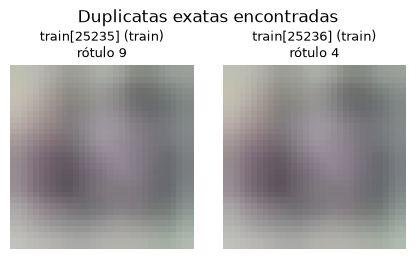

In [3]:
from svhn_utils import SEED_SPLIT, VAL_FRACTION, stratified_split
import torch

_, va_idx = stratified_split(torch.from_numpy(raw["train"].labels).long(), VAL_FRACTION, SEED_SPLIT)
va_set = set(va_idx.tolist())

groups = [g for s in dups for g in dups[s]]
fig, axes = plt.subplots(1, sum(map(len, groups)), figsize=(2.2 * sum(map(len, groups)), 2.6), squeeze=False)
k = 0
for s in dups:
    for g in dups[s]:
        for i in g:
            part = "validação" if (s == "train" and i in va_set) else s
            axes[0, k].imshow(raw[s].data[i].transpose(1, 2, 0)); axes[0, k].axis("off")
            axes[0, k].set_title(f"{s}[{i}] ({part})\nrótulo {raw[s].labels[i]}", fontsize=9)
            k += 1
plt.suptitle("Duplicatas exatas encontradas"); plt.tight_layout()
plt.savefig(FIG_DIR / "duplicates.png", dpi=150); plt.show()

## Imagens degeneradas

Uso o desvio padrão dos pixels de cada imagem como medida simples de contraste: uma imagem uniforme
(sem dígito visível) teria desvio próximo de zero.

contraste: mínimo 0.035 | percentil 1 0.056 | mediana 0.115
imagens com desvio < 0,02 (praticamente uniformes): 0


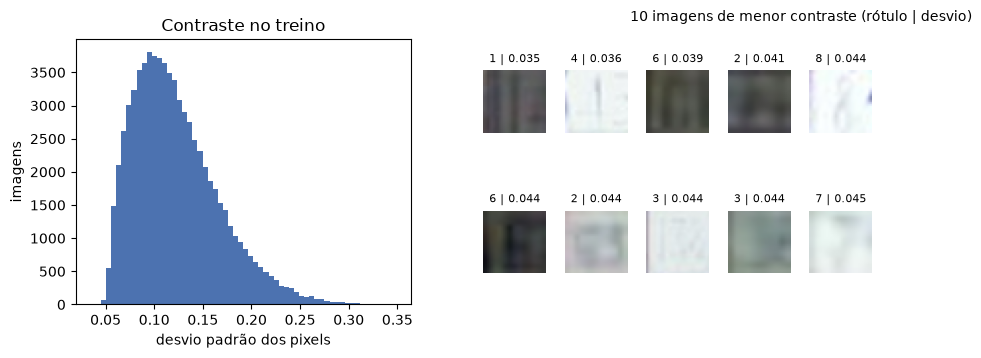

In [4]:
X = raw["train"].data.astype(np.float32) / 255
contrast = X.reshape(len(X), -1).std(1)
print(f"contraste: mínimo {contrast.min():.3f} | percentil 1 {np.percentile(contrast, 1):.3f} | "
      f"mediana {np.median(contrast):.3f}")
print(f"imagens com desvio < 0,02 (praticamente uniformes): {(contrast < 0.02).sum()}")

fig = plt.figure(figsize=(13, 3.6))
ax = fig.add_subplot(1, 3, 1)
ax.hist(contrast, bins=60, color="#4C72B0"); ax.set_xlabel("desvio padrão dos pixels"); ax.set_ylabel("imagens")
ax.set_title("Contraste no treino")
low = np.argsort(contrast)[:10]
for k, i in enumerate(low):
    a = fig.add_subplot(2, 15, 6 + k + (k // 5) * 10)
    a.imshow(raw["train"].data[i].transpose(1, 2, 0)); a.axis("off")
    a.set_title(f"{raw['train'].labels[i]} | {contrast[i]:.3f}", fontsize=8)
fig.text(0.62, 0.95, "10 imagens de menor contraste (rótulo | desvio)", ha="center", fontsize=10)
plt.tight_layout(); plt.savefig(FIG_DIR / "low_contrast.png", dpi=150); plt.show()

## Conclusão e decisão

- **Integridade:** sem problemas. Todas as imagens são RGB 32×32 em uint8 e os rótulos estão entre 0 e 9 (o
  `torchvision` já converte o rótulo 10 do arquivo original para o dígito 0).
- **Vazamento:** nenhuma imagem do teste aparece no treino, então a acurácia de teste não está inflada por cópias.
- **Duplicatas:** há um único par de imagens idênticas no treino (índices 25235 e 25236, gravadas em sequência),
  com **rótulos diferentes** (9 e 4). A imagem é borrada demais para saber qual é o dígito: um primeiro sinal de
  que o dataset tem erros de rotulagem.
- **Contraste:** nenhuma imagem é uniforme; as de menor contraste são escuras ou borradas, mas ainda contêm
  informação.

**Decisão:** não removi nem corrigi nenhuma imagem. O par duplicado é irrelevante perto de 73 mil imagens, e
manter os splits oficiais intactos deixa os resultados comparáveis com outros trabalhos no SVHN. O tamanho do
problema de rótulos errados é medido no notebook [8](08_label_noise_audit.ipynb).